# 01 · Tokenizer analysis (descriptive)

**Question:** how many tokens do different models need for the same terms in EN / RU / KK?

This is a *descriptive* analysis: it is already known that Kazakh is tokenized less efficiently.
The value is the numbers on our domain (vocational terms) and the link to the later model evaluation.

Metrics:
- **tokens per term** — mean and median;
- **fertility** = tokens per whitespace-separated word (fairer, because terms differ in length).

Special tokens (BOS/EOS, language tags) are **not** counted.

In [1]:
# Colab: uncomment
# !pip -q install transformers sentencepiece protobuf tiktoken pandas matplotlib

In [2]:
from pathlib import Path
import pandas as pd

# Local repo or Colab: point to terms.csv (or a raw GitHub URL)
CANDIDATES = [Path("../data/terms.csv"), Path("data/terms.csv"), Path("kazprofterm/data/terms.csv")]
TERMS_PATH = next((p for p in CANDIDATES if p.exists()), None)
# TERMS_PATH = "https://raw.githubusercontent.com/<user>/kazprofterm/main/data/terms.csv"

terms = pd.read_csv(TERMS_PATH, dtype=str).fillna("")
print(len(terms), "terms")
print(terms["specialty"].value_counts())
assert len(terms) > 0, "terms.csv is empty — add terms first"
RESULTS = Path("../results") if Path("../results").exists() else Path("results")
RESULTS.mkdir(exist_ok=True)

100 terms
specialty
it_technician    34
electrician      33
cook             33
Name: count, dtype: int64


## Tokenizers

KazLLM (ISSAI) and some LLMs are *gated*: accept the terms on the model page and run
`huggingface_hub.login()` first. Models that fail to load are skipped with a message.

In [3]:
from transformers import AutoTokenizer

MODELS = {
    "mBERT":        "bert-base-multilingual-cased",
    "XLM-R":        "xlm-roberta-base",
    "NLLB-200":     "facebook/nllb-200-distilled-600M",
    "Qwen2.5":      "Qwen/Qwen2.5-7B-Instruct",
    "KazLLM (ISSAI)": "issai/LLama-3.1-KazLLM-1.0-8B",   # gated; check the exact repo id on the Hub
}

tokenizers = {}
for name, repo in MODELS.items():
    try:
        tokenizers[name] = AutoTokenizer.from_pretrained(repo)
        print(f"ok    {name:16s} {repo}")
    except Exception as e:
        print(f"SKIP  {name:16s} {repo}: {type(e).__name__}: {str(e)[:120]}")

ok    mBERT            bert-base-multilingual-cased


ok    XLM-R            xlm-roberta-base


ok    NLLB-200         facebook/nllb-200-distilled-600M


ok    Qwen2.5          Qwen/Qwen2.5-7B-Instruct


SKIP  KazLLM (ISSAI)   issai/LLama-3.1-KazLLM-1.0-8B: OSError: You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/issai/LLama-3.1-KazLLM-1


In [4]:
LANGS = ["en", "ru", "kk"]

def n_tokens(tok, text):
    return len(tok(text, add_special_tokens=False)["input_ids"])

rows = []
for name, tok in tokenizers.items():
    for _, t in terms.iterrows():
        for lang in LANGS:
            text = t[lang].strip()
            if not text:
                continue
            n_tok = n_tokens(tok, text)
            n_words = len(text.split())
            rows.append({"model": name, "id": t["id"], "specialty": t["specialty"],
                         "term_type": t["term_type"], "lang": lang, "text": text,
                         "tokens": n_tok, "words": n_words, "fertility": n_tok / n_words})
long = pd.DataFrame(rows)
long.to_csv(RESULTS / "tokenizers_long.csv", index=False)
long.head()

,model,id,specialty,term_type,lang,text,tokens,words,fertility
0,mBERT,T0001,it_technician,calque,en,operating system,2,2,1.0
1,mBERT,T0001,it_technician,calque,ru,операционная система,3,2,1.5
2,mBERT,T0001,it_technician,calque,kk,операциялық жүйе,3,2,1.5
3,mBERT,T0002,it_technician,calque,en,database,1,1,1.0
4,mBERT,T0002,it_technician,calque,ru,база данных,2,2,1.0


## Summary table: model × language

In [5]:
summary = (long.groupby(["model", "lang"])
               .agg(tokens_mean=("tokens", "mean"), tokens_median=("tokens", "median"),
                    fertility_mean=("fertility", "mean"), n=("id", "nunique"))
               .round(2)
               .reset_index())
wide = summary.pivot(index="model", columns="lang", values=["tokens_mean", "fertility_mean"])
wide = wide.reindex(columns=LANGS, level=1)
wide.columns = [f"{m}_{l}" for m, l in wide.columns]
# ratio KK / EN per term (mean of per-term ratios)
per_term = long.pivot_table(index=["model", "id"], columns="lang", values="tokens").reset_index()
ratio = (per_term.assign(kk_en=per_term["kk"] / per_term["en"], ru_en=per_term["ru"] / per_term["en"])
                 .groupby("model")[["kk_en", "ru_en"]].mean().round(2))
table = wide.join(ratio)
summary.to_csv(RESULTS / "tokenizers_summary.csv", index=False)
table.to_csv(RESULTS / "tokenizers_table.csv")
table

,tokens_mean_en,tokens_mean_ru,tokens_mean_kk,fertility_mean_en,fertility_mean_ru,fertility_mean_kk,kk_en,ru_en
model,,,,,,,,
NLLB-200,2.56,4.46,4.28,1.73,2.66,2.34,1.84,1.90
Qwen2.5,2.28,5.68,9.56,1.56,3.37,4.89,4.43,2.72
XLM-R,2.46,3.58,4.31,1.66,2.13,2.33,1.86,1.54
mBERT,2.50,4.85,6.38,1.68,2.89,3.42,2.79,2.15


## Figure: mean fertility (tokens per word)

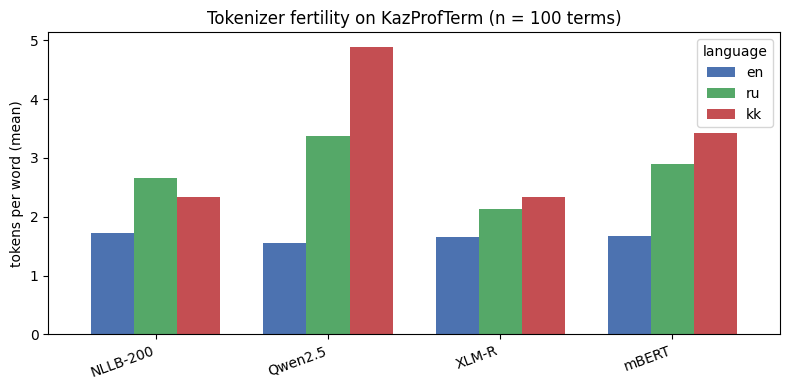

In [6]:
import matplotlib.pyplot as plt

fig_df = summary.pivot(index="model", columns="lang", values="fertility_mean")[LANGS]
ax = fig_df.plot(kind="bar", figsize=(8, 4), width=0.75, color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_ylabel("tokens per word (mean)")
ax.set_xlabel("")
ax.set_title(f"Tokenizer fertility on KazProfTerm (n = {terms['id'].nunique()} terms)")
ax.legend(title="language")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(RESULTS / "tokenizers_fertility.png", dpi=200)
plt.show()

## Breakdown by specialty and term type (Kazakh only)

In [7]:
kk = long[long["lang"] == "kk"]
display(kk.pivot_table(index="model", columns="specialty", values="fertility", aggfunc="mean").round(2))
display(kk.pivot_table(index="model", columns="term_type", values="fertility", aggfunc="mean").round(2))

specialty,cook,electrician,it_technician
model,,,
NLLB-200,2.68,2.33,2.02
Qwen2.5,4.87,4.92,4.89
XLM-R,2.73,2.26,2.03
mBERT,3.67,3.49,3.09


term_type,borrowing,calque,hybrid,native
model,,,,
NLLB-200,2.38,2.14,2.25,3.00
Qwen2.5,3.54,5.29,4.64,5.38
XLM-R,1.62,2.32,2.20,3.19
mBERT,2.92,3.47,3.18,4.06


## Most fragmented Kazakh terms (examples for the report)

In [8]:
for name, tok in tokenizers.items():
    top = kk[kk["model"] == name].nlargest(3, "fertility")
    print(f"--- {name}")
    for _, r in top.iterrows():
        ids = tok(r["text"], add_special_tokens=False)["input_ids"]
        pieces = [tok.decode([i]) for i in ids]  # readable even for byte-level BPE (Qwen)
        print(f"  {r['text']!r}: {r['tokens']} tokens -> {pieces}")

--- mBERT
  'сақтандырғыш': 6 tokens -> ['са', '##қ', '##тан', '##ды', '##рғы', '##ш']
  'трансформатор': 6 tokens -> ['т', '##ран', '##с', '##фор', '##мат', '##ор']
  'өткізгіш': 6 tokens -> ['ө', '##т', '##кі', '##з', '##гі', '##ш']
--- XLM-R
  'залалсыздандыру': 6 tokens -> ['за', 'лал', 'сыз', 'дан', 'дыр', 'у']
  'оқшаулағыш': 5 tokens -> ['оқ', 'ша', 'у', 'ла', 'ғыш']
  'тоңазытқыш': 5 tokens -> ['то', 'ң', 'а', 'зы', 'тқыш']
--- NLLB-200
  'тоңазытқыш': 5 tokens -> ['то', 'ңа', 'зы', 'т', 'қыш']
  'маршрутизатор': 4 tokens -> ['маршру', 'ти', 'за', 'тор']
  'сақтандырғыш': 4 tokens -> ['сақ', 'тан', 'дыр', 'ғыш']
--- Qwen2.5
  'азық-түлік қауіпсіздігі': 21 tokens -> ['аз', 'ы', 'қ', '-', 'т', 'ү', 'л', 'і', 'к', ' ', 'қ', 'а', 'у', 'і', 'п', 'с', 'і', 'зд', 'і', 'г', 'і']
  'сақтандырғыш': 8 tokens -> ['са', 'қ', 'т', 'анд', 'ы', 'р', 'ғ', 'ыш']
  'өткізгіш': 8 tokens -> ['ө', 'т', 'к', 'і', 'з', 'г', 'і', 'ш']


## Findings (draft — check the numbers after re-running)

- On our 100 terms, Kazakh terms need more tokens than their English equivalents in all four tokenizers: on average **1.8×** (NLLB-200, XLM-R), **2.8×** (mBERT) and **4.4×** (Qwen2.5).
- In NLLB-200 and XLM-R, Kazakh fertility (2.3 tokens per word) is close to Russian (2.7 and 2.1), whereas the general-purpose LLM tokenizer (Qwen2.5) is much less efficient on Kazakh (4.9 tokens per word vs 3.4 for Russian and 1.6 for English); it often falls back to single bytes for Kazakh-specific letters (қ, ғ, ү, і, ө).
- Native Kazakh terms are split more finely than borrowings in every model (e.g. XLM-R: 3.2 vs 1.6 tokens per word): borrowed words such as «трансформатор» reuse Russian sub-words, native ones do not.
- This is a descriptive result on a small domain sample (n = 100) and agrees with what is already known about Kazakh tokenization; KazLLM (ISSAI) was not included because the repository is gated.